In [29]:
# Indice

# Bloque 1- Librerías necesarias

# Bloque 2- clase NumericalDifferentiation

# Bloque 3- ejercicio 2.a

# Bloque 4- ejercicio 2.b

In [30]:
import numpy as np
import matplotlib.pyplot as plt

In [31]:
# Se define Clase que implementa tres métodos de diferenciación numérica
class NumericalDifferentiation:

    # Constructor de la clase
    def __init__(self, f, a, b, n):

        # Guardamos la función a derivar
        self.f = f

        # Extremos del intervalo
        self.a = a
        self.b = b

        # Cantidad de puntos
        self.n = n

        # Genera n puntos equiespaciados entre a y b
        self.x = np.linspace(a, b, n)

        # Calcula el paso entre puntos consecutivos
        self.h = (b - a) / (n - 1)

    # Diferenciación hacia adelante. metodo que implementa la fórmula de diferencia hacia adelante para aproximar 
    # la derivada de una función en un conjunto de puntos. La función recorre los puntos del intervalo definido por 
    # el usuario, calculando la derivada en cada punto utilizando la diferencia entre el valor de la función 
    # en el punto siguiente y el valor de la función en el punto actual, dividido por el paso entre los puntos.
    # Los resultados se almacenan en listas que luego se convierten a arrays de NumPy para su posterior uso.
    def forward(self):

        # Lista donde se almacenarán las derivadas
        dy = []

        # Lista donde se almacenarán los x válidos
        X = []

        # Recorremos hasta n-2 porque usamos i+1
        for i in range(self.n - 1):

            # Fórmula de diferencia hacia adelante
            derivative = (self.f(self.x[i + 1]) - self.f(self.x[i])) / self.h

            # Guardamos la derivada calculada
            dy.append(derivative)

            # Guardamos el punto donde es válida
            X.append(self.x[i])

        # Convertimos las listas a arrays de NumPy
        return np.array(dy), np.array(X)

    # Diferenciación hacia atrás, metodo que implementa la fórmula de diferencia hacia atrás para aproximar 
    # la derivada de una función en un conjunto de puntos. La función recorre los puntos del intervalo definido 
    # por el usuario, calculando la derivada en cada punto utilizando la diferencia entre el valor de la función 
    # en el punto actual y el valor de la función en el punto anterior, dividido por el paso entre los puntos. 
    # Los resultados se almacenan en listas que luego se convierten a arrays de NumPy para su posterior uso.
    def backward(self):

        dy = []
        X = []

        # Comenzamos en 1 porque usamos i-1
        for i in range(1, self.n):

            # Fórmula de diferencia hacia atrás
            derivative = ( self.f(self.x[i]) - self.f(self.x[i - 1]) ) / self.h

            dy.append(derivative)

            X.append(self.x[i])

        return np.array(dy), np.array(X)

    # Diferenciación centrada. Metodo que implementa la fórmula de diferencia centrada para aproximar la derivada 
    # de una función en un conjunto de puntos. La función recorre los puntos del intervalo definido por el usuario, 
    # calculando la derivada en cada punto utilizando la diferencia entre el valor de la función en el punto 
    # siguiente y el valor de la función en el punto anterior, dividido por el doble del paso entre los puntos. 
    # os resultados se almacenan en listas que luego se convierten a arrays de NumPy para su posterior uso.
   
    def central(self):

        dy = []
        X = []

        # Comenzamos en 1 y terminamos en n-2
        # porque necesitamos un punto a izquierda y otro a derecha
        for i in range(1, self.n - 1):

            # Fórmula de diferencia centrada
            derivative = ( self.f(self.x[i + 1]) - self.f(self.x[i - 1])) / (2 * self.h)

            dy.append(derivative)

            X.append(self.x[i])

        return np.array(dy), np.array(X)

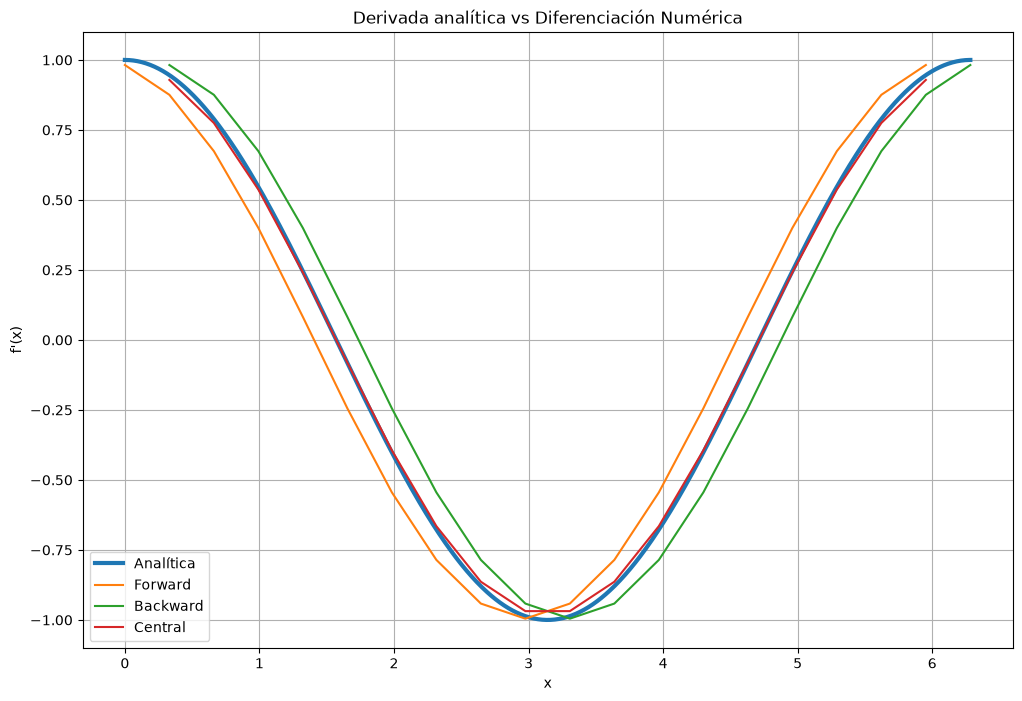

In [32]:
# =====================================================
# EJERCICIO 2.a
# Comparación entre la derivada analítica de sin(x)
# y las aproximaciones numéricas:
#   - Forward
#   - Backward
#   - Central
# =====================================================

# Definimos la función a derivar
f = lambda x: np.sin(x)

# Creamos un objeto de la clase utilizando el intervalo [0, 2*pi] y 100 puntos
num_diff = NumericalDifferentiation(
    f,
    0,
    2*np.pi,
    20
)

# Derivación numérica hacia adelante
dyf, Xf = num_diff.forward()

# Derivación numérica hacia atrás
dyb, Xb = num_diff.backward()

# Derivación numérica centrada
dyc, Xc = num_diff.central()

# Vector para representar la derivada exacta
x = np.linspace(
    0,
    2*np.pi,
    1000
)

# Derivada analítica:
# d/dx [sin(x)] = cos(x)
analytic = np.cos(x)

# Crear figura
plt.figure(figsize=(12,8))

# Derivada exacta
plt.plot(
    x,
    analytic,
    label="Analítica",
    linewidth=3
)

# Diferenciación hacia adelante
plt.plot(
    Xf,
    dyf,
    label="Forward"
)

# Diferenciación hacia atrás
plt.plot(
    Xb,
    dyb,
    label="Backward"
)

# Diferenciación centrada
plt.plot(
    Xc,
    dyc,
    label="Central"
)

# Leyenda
plt.legend()

# Título
plt.title(
    "Derivada analítica vs Diferenciación Numérica"
)

# Etiquetas de ejes
plt.xlabel("x")
plt.ylabel("f'(x)")

# Agrega cuadrícula
plt.grid(True)

# Mostrar gráfico
plt.show()

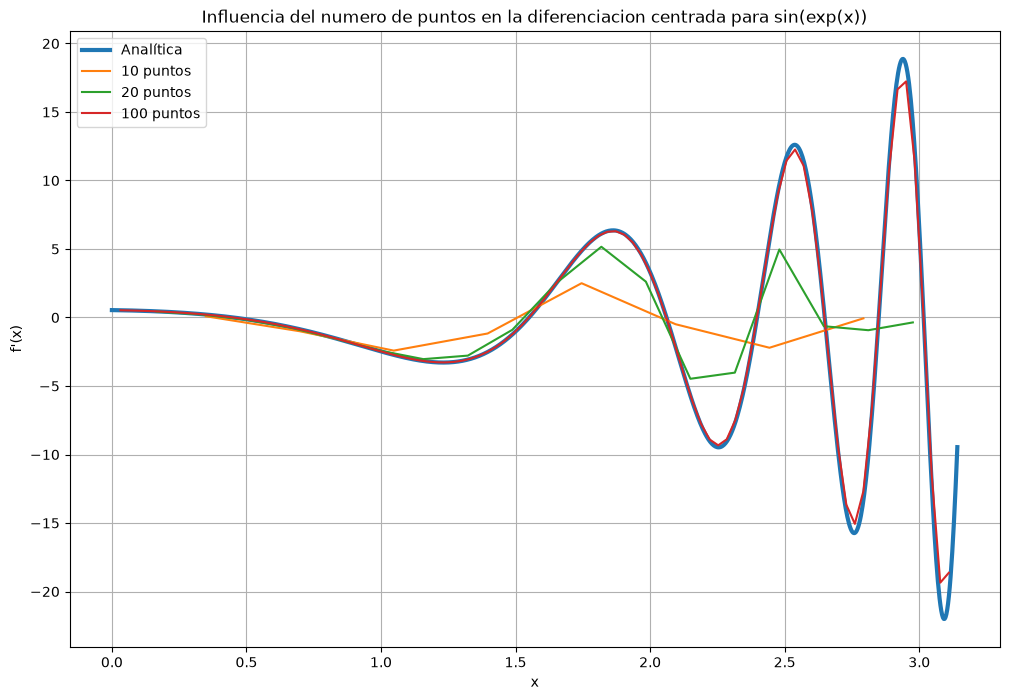

In [33]:
# =====================================================
# EJERCICIO 2.b
# Estudio de la influencia de la cantidad de puntos utilizando diferenciación centrada para la función:
# f(x) = sen(e^x)
# Se comparan tres discretizaciones:
#   - 10 puntos
#   - 20 puntos
#   - 100 puntos
# contra la derivada analítica.
# =====================================================

# Definimos la función a derivar
f = lambda x: np.sin(np.exp(x))

# -----------------------------------------------------
# CASO 1: n = 10 puntos
# -----------------------------------------------------

# Se crea un objeto utilizando 10 puntos
diff10 = NumericalDifferentiation(
    f,
    0,
    np.pi,
    10
)

# Se calcula la derivada mediante
# diferencias centradas
dy10, X10 = diff10.central()

# -----------------------------------------------------
# CASO 2: n = 20 puntos
# -----------------------------------------------------

diff20 = NumericalDifferentiation(
    f,
    0,
    np.pi,
    20
)

dy20, X20 = diff20.central()

# -----------------------------------------------------
# CASO 3: n = 100 puntos
# -----------------------------------------------------

diff100 = NumericalDifferentiation(
    f,
    0,
    np.pi,
    100
)

dy100, X100 = diff100.central()

# -----------------------------------------------------
# DERIVADA ANALÍTICA
# -----------------------------------------------------

# Genera un vector mucho más fino para obtener
# una representación suave de la solución exacta

x = np.linspace(
    0,
    np.pi,
    1000
)

# La función es:
# f(x) = sen(e^x)
# Aplicando regla de la cadena:
# f'(x)
# = cos(e^x) · d/dx(e^x)
# como:
# d/dx(e^x)=e^x
# entonces:
# f'(x)=e^x cos(e^x)

analytic = (
    np.exp(x)
    * np.cos(np.exp(x))
)

# -----------------------------------------------------
# GRÁFICO
# -----------------------------------------------------

plt.figure(figsize=(12,8))

# Curva analítica
plt.plot(
    x,
    analytic,
    label="Analítica",
    linewidth=3
)

# Diferenciación centrada con 10 puntos
plt.plot(
    X10,
    dy10,
    label="10 puntos"
)

# Diferenciación centrada con 20 puntos
plt.plot(
    X20,
    dy20,
    label="20 puntos"
)

# Diferenciación centrada con 100 puntos
plt.plot(
    X100,
    dy100,
    label="100 puntos"
)

# Muestra leyenda
plt.legend()

# Título del gráfico
plt.title(
    "Influencia del numero de puntos en la diferenciacion centrada para sin(exp(x))"
)

# Etiqueta eje X
plt.xlabel("x")

# Etiqueta eje Y
plt.ylabel("f'(x)")

# Agrega grilla
plt.grid(True)

# Muestra la figura
plt.show()